In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.linear_model import LinearRegression
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

In [2]:
df =  pd.read_csv(r"C:\Users\user\PycharmProjects\PythonWorkspace\practice_dataset.csv")
df.head()

,Hours_Studied,Exam_Score
0,6.25,44.62
1,8.97,59.80
2,7.76,47.80
3,2.25,16.20
4,3.00,23.44


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Hours_Studied  500 non-null    float64
 1   Exam_Score     500 non-null    float64
dtypes: float64(2)
memory usage: 7.9 KB


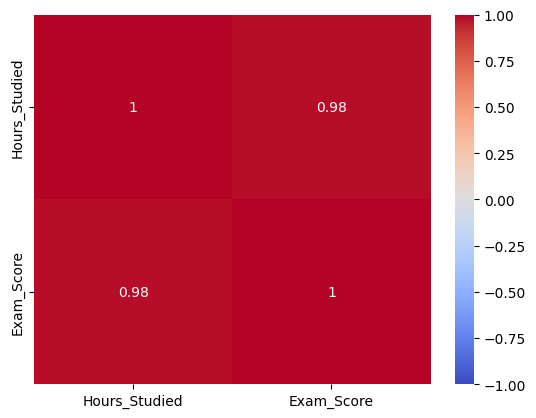

In [4]:
corr = df.corr(numeric_only = True)
sns.heatmap(corr, annot = True, vmin = -1, vmax = 1, cmap = 'coolwarm')
plt.show()

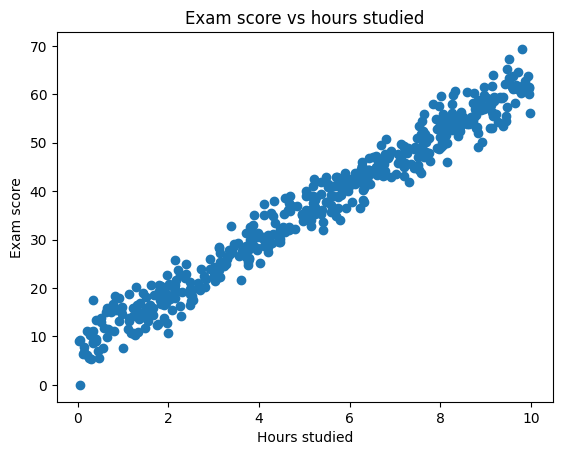

In [5]:
plt.scatter(df["Hours_Studied"], df["Exam_Score"])
plt.title("Exam score vs hours studied")
plt.ylabel("Exam score")
plt.xlabel("Hours studied")
plt.show()

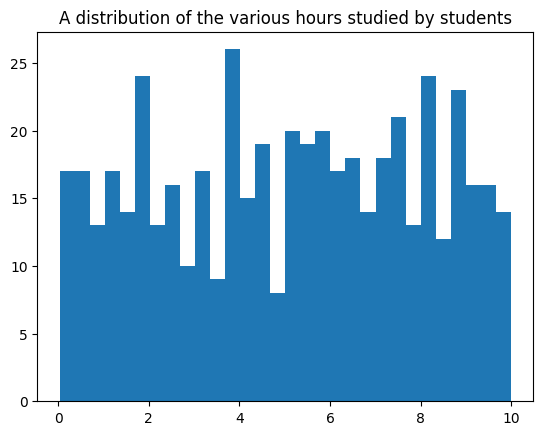

In [6]:
plt.hist(df['Hours_Studied'], bins = 30)
plt.title("A distribution of the various hours studied by students")
plt.show()

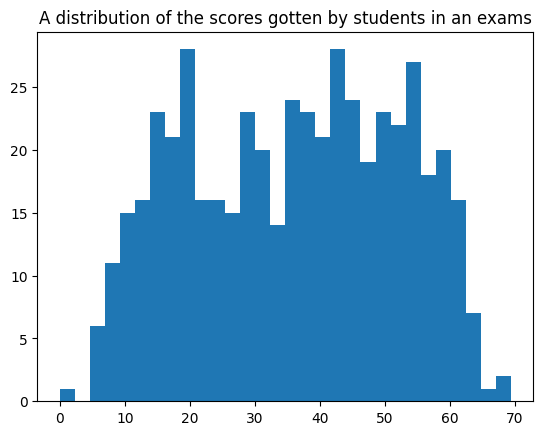

In [7]:
plt.hist(df['Exam_Score'], bins = 30)
plt.title("A distribution of the scores gotten by students in an exams")
plt.show()

In [112]:
x = np.array(df['Hours_Studied']).reshape(-1, 1)
y = np.array(df['Exam_Score']).reshape(-1, 1)

In [113]:
x_train, x_test, y_train, y_test = train_test_split(x, y, random_state = 42, test_size = 0.2)

### Building the model (vectorization to improve efficiency and speed)

In [114]:
def linreg_model(w,b, x):
    """w is an array of shape (1,n)
       b is a number
       x is an array of shape (m,n)
    """
    x = np.transpose(x)
    y_pred = np.matmul(w, x) + b
    y_hat = np.transpose(y_pred)
    return y_hat   #y_hat has a shape of (1,m)

In [123]:
m,n = x_train.shape
w = np.zeros(n).reshape(1, -1)
b = 0
alpha = 0.001
iterations = 100000
iters, costs = [], []

In [124]:
for iteration in range(iterations):    
    y_hat = linreg_model(w, b, x_train)
    # print(y_hat.shape)
    loss = y_hat - y_train
    # print(loss.shape)
    cost = 0.5*np.mean(loss**2)
    dw = (1 / m) * np.dot(loss.T, x_train)
    w = w - alpha * dw
    b = b - alpha*np.mean(loss)

    if (iteration % 100)==0:
        print(f"Iteration:   {iteration}")
        print(f"Cost:   {cost}")
        iters.append(iteration)
        costs.append(cost)

Iteration:   0
Cost:   773.59956275
Iteration:   100
Cost:   10.181161221250743
Iteration:   200
Cost:   9.283244376203024
Iteration:   300
Cost:   9.048685616719299
Iteration:   400
Cost:   8.825549478449515
Iteration:   500
Cost:   8.612774498523532
Iteration:   600
Cost:   8.40987913137779
Iteration:   700
Cost:   8.216404644376096
Iteration:   800
Cost:   8.031913605239916
Iteration:   900
Cost:   7.855988892638149
Iteration:   1000
Cost:   7.688232753104625
Iteration:   1100
Cost:   7.52826590174534
Iteration:   1200
Cost:   7.375726664701866
Iteration:   1300
Cost:   7.230270161432037
Iteration:   1400
Cost:   7.091567524959194
Iteration:   1500
Cost:   6.959305158326958
Iteration:   1600
Cost:   6.833184025578442
Iteration:   1700
Cost:   6.712918975656887
Iteration:   1800
Cost:   6.598238097699075
Iteration:   1900
Cost:   6.4888821062638815
Iteration:   2000
Cost:   6.3846037551060375
Iteration:   2100
Cost:   6.285167278169677
Iteration:   2200
Cost:   6.190347856537773
Iter

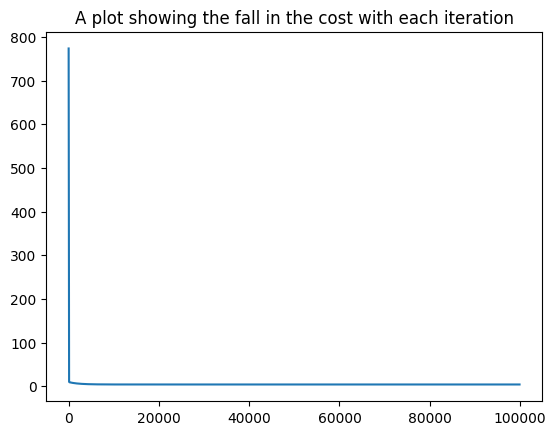

In [125]:
plt.title("A plot showing the fall in the cost with each iteration")
plt.plot(iters , costs)
plt.show()

In [126]:
print(f"Model Parameters:")
print(f"Weight: {w}")
print(f"Bias: {b}")

Model Parameters:
Weight: [[5.54518861]]
Bias: 7.739643468503275


In [119]:
y_predicted = linreg_model(w,b, x_test)
# print(type(x_test))
# print(y_predicted[0:10], y_test[0:10])
r2 = r2_score(y_test, y_predicted)
mae = mean_absolute_error(y_test, y_predicted)
mse = mean_squared_error(y_test, y_predicted)

print(f"Mean Squared Error: {mse}")
print(f"Mean Absolute Error: {mae}")
print(f"R Squared: {r2}")

Mean Squared Error: 7.174725825426973
Mean Absolute Error: 2.0575695661074707
R Squared: 0.9698867484612433


### Making a visual representation of our model

In [120]:
y_pred_final = linreg_model(w,b, x_train)

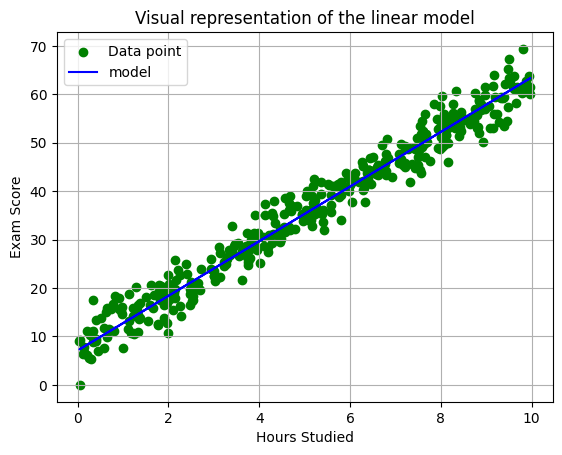

In [127]:
plt.scatter(x_train, y_train, color = 'green', label = 'Data point')
plt.plot(x_train, y_pred_final, color = 'blue', label =  'model')
plt.title("Visual representation of the linear model")
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.legend()
plt.grid()
plt.show()

### Writing a sklearn model to compare my results

In [128]:
x_train2d = x_train.reshape(-1, 1)
y_train2d = y_train.reshape(-1, 1)
x_test2d = x_test.reshape(-1, 1)
y_test2d = y_test.reshape(-1, 1)
model2 = LinearRegression()

In [129]:
model2.fit(x_train2d, y_train2d)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[5.55]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[7.74]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[57.44]


In [130]:
print(f"Model weight: {model2.coef_}")
print(f"Model intercept: {model2.intercept_}")

Model weight: [[5.54518861]]
Model intercept: [7.73964347]


In [131]:
y_pred2 = model2.predict(x_test2d)
# print(type(x_test))
# print(y_predicted[0:10], y_test[0:10])
r2 = r2_score(y_test2d, y_pred2)
mae = mean_absolute_error(y_test2d, y_pred2)
mse = mean_squared_error(y_test2d, y_pred2)

print(f"Mean Squared Error: {mse}")
print(f"Mean Absolute Error: {mae}")
print(f"R Squared: {r2}")

Mean Squared Error: 7.105004219053278
Mean Absolute Error: 2.0712003746797705
R Squared: 0.9701793790538963
